**Use Python (Pandas, Seaborn, Matplotlib) to analyze a health dataset with BMI, age, gender, and lifestyle factors. Perform statistical summaries and visualize the relationships to identify groups at health risk.**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv("health_lifestyle.csv")
cat_order = ["Underweight", "Normal", "Overweight", "Obese"]
df["bmi_category"] = pd.Categorical(df["bmi_category"], categories=cat_order,
                                    ordered=True)

# ----------------------------------------------------------------
# 1. STRUCTURE & STATISTICAL SUMMARIES
# ----------------------------------------------------------------
print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)
print(df.info())
print("\nMissing values:\n", df.isnull().sum())

print("\n" + "=" * 70)
print("DESCRIPTIVE STATISTICS (numeric columns)")
print("=" * 70)
print(df.describe().round(2))

print("\n" + "=" * 70)
print("BMI SUMMARY BY GENDER")
print("=" * 70)
print(df.groupby("gender")["bmi"].agg(["mean", "median", "std", "min", "max"]).round(2))

print("\n" + "=" * 70)
print("BMI CATEGORY COUNTS")
print("=" * 70)
print(df["bmi_category"].value_counts().reindex(cat_order))


print("\n" + "=" * 70)
print("CORRELATION MATRIX (numeric features)")
print("=" * 70)
num_cols = ["age", "bmi", "exercise_hours_week", "diet_quality_score", "sleep_hours", "alcohol_units_week"]
corr = df[num_cols].corr().round(2)
print(corr)

DATASET OVERVIEW
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   age                  1000 non-null   int64   
 1   gender               1000 non-null   object  
 2   height_cm            1000 non-null   float64 
 3   weight_kg            1000 non-null   float64 
 4   bmi                  1000 non-null   float64 
 5   bmi_category         1000 non-null   category
 6   smoker               1000 non-null   object  
 7   exercise_hours_week  1000 non-null   float64 
 8   diet_quality_score   1000 non-null   float64 
 9   sleep_hours          1000 non-null   float64 
 10  alcohol_units_week   1000 non-null   float64 
 11  Unnamed: 11          0 non-null      float64 
dtypes: category(1), float64(8), int64(1), object(2)
memory usage: 87.2+ KB
None

Missing values:
 age                       0
gender                    0
height_c

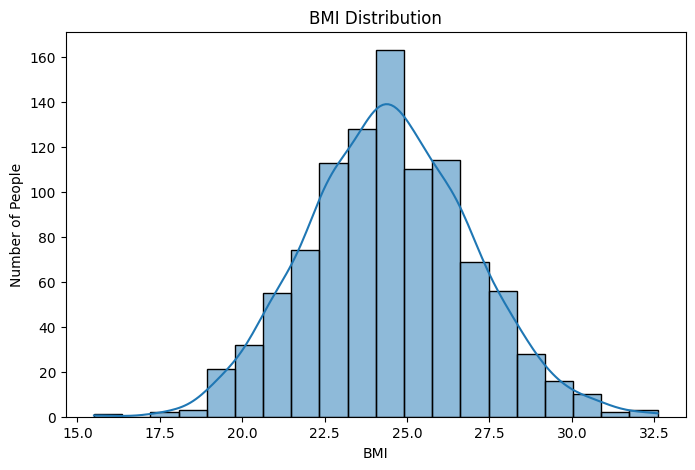

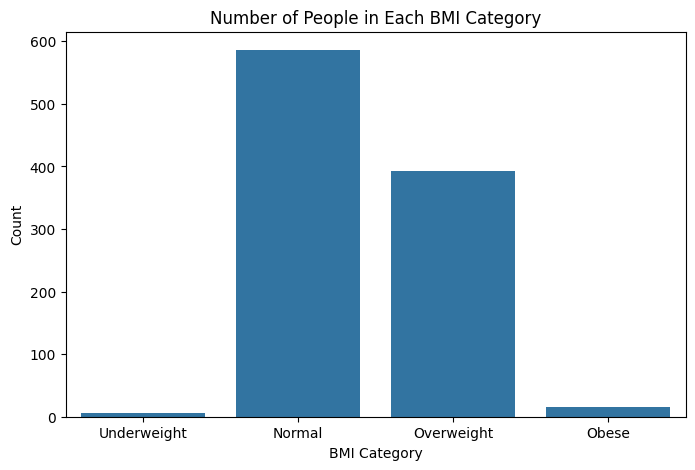

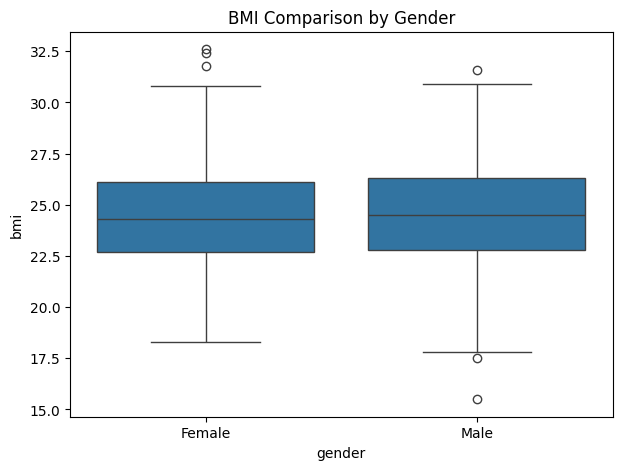

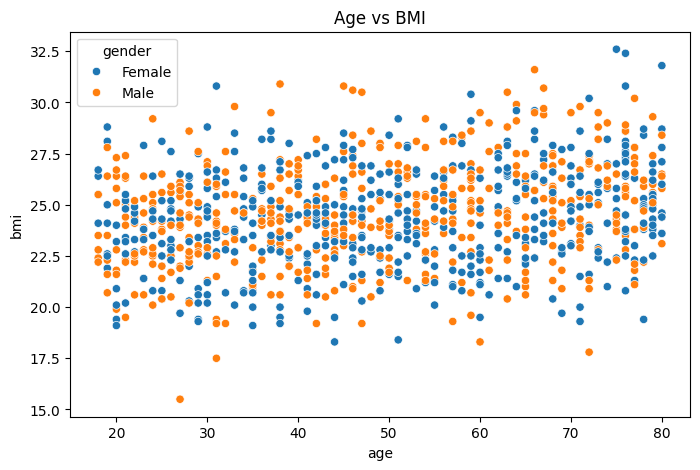

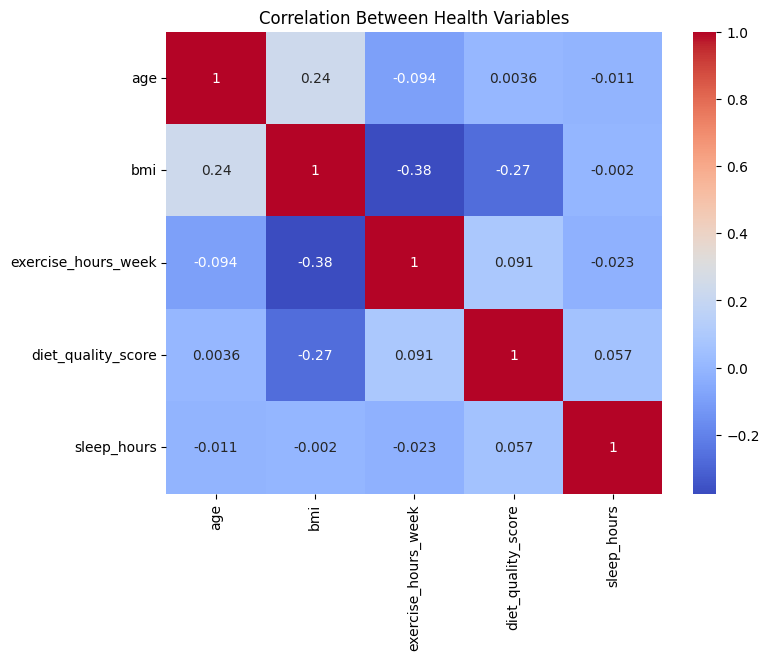

In [ ]:
# ==================================================
# DATA VISUALIZATION
# ==================================================

# 1. BMI Distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["bmi"], bins=20, kde=True)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of People")

plt.show()


# 2. BMI Category Count
plt.figure(figsize=(8, 5))

sns.countplot( data=df, x="bmi_category", order=cat_order)

plt.title("Number of People in Each BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Count")

plt.show()


# 3. BMI Comparison by Gender
plt.figure(figsize=(7, 5))

sns.boxplot( data=df, x="gender", y="bmi")

plt.title("BMI Comparison by Gender")

plt.show()


# 4. Age vs BMI
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="bmi",
    hue="gender"
)

plt.title("Age vs BMI")

plt.show()


# 5. Correlation Heatmap
numeric_columns = [
    "age",
    "bmi",
    "exercise_hours_week",
    "diet_quality_score",
    "sleep_hours"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Health Variables")

plt.show()



Cluster Summary:

           age    bmi  exercise_hours_week
cluster                                   
0        45.61  22.59                 5.06
1        66.92  26.20                 2.00
2        34.22  24.69                 1.83


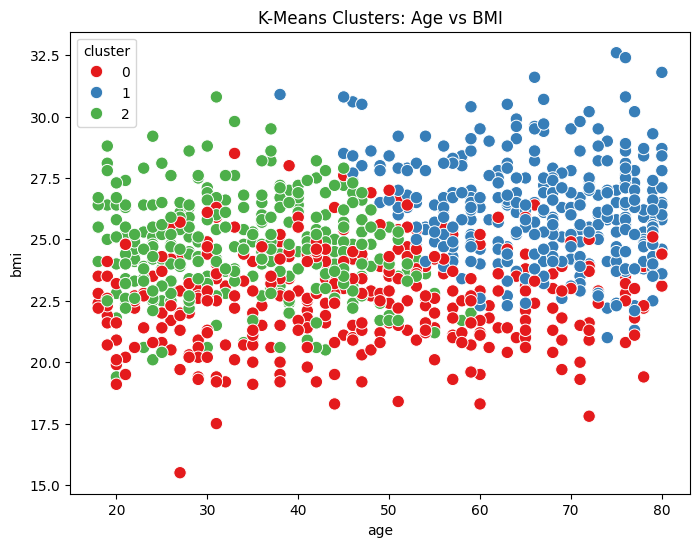

In [ ]:
# ==================================================
# K-MEANS CLUSTERING
# ==================================================

# Step 1: Select features
features = [
    "age",
    "bmi",
    "exercise_hours_week"
]

X = df[features]


# Step 2: Scale the data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# Step 3: Create K-Means model
kmeans = KMeans( n_clusters=3, random_state=42, n_init=10)


# Step 4: Assign cluster labels
df["cluster"] = kmeans.fit_predict(X_scaled)


# Step 5: Display cluster averages
print("\nCluster Summary:\n")

print(
    df.groupby("cluster")[features].mean().round(2)
)


# Step 6: Visualize clusters
plt.figure(figsize=(8, 6))

sns.scatterplot( data=df, x="age", y="bmi", hue="cluster", palette="Set1", s=80)

plt.title("K-Means Clusters: Age vs BMI")

plt.show()




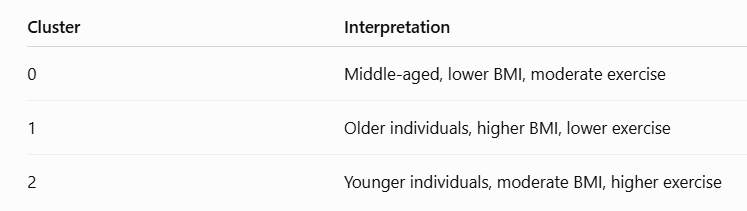

#LAB PROGRAM 3

 ## **Using Python(Pandas, Matplotlib, Seaborn), clean the Titanic dataset and create histograms of age, bar charts of passenger class, heatmaps of feature correlations, and pair plots of survival**

**The steps involved in this program:**

1.   Load Titanic dataset
2.   Understand the data
1.   Clean missing values
2.   Create an Age histogram
1.   Create Passenger Class bar charts
1.   Create a correlation heatmap
2.   Create a pair plot based on survival








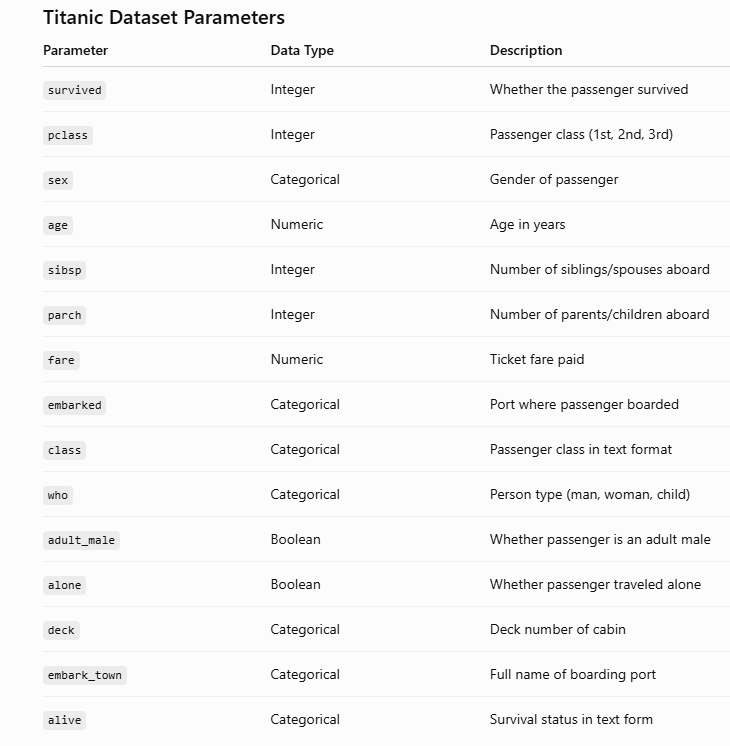

In [ ]:
# ============================================
# TITANIC DATASET - BEGINNER LEVEL EDA
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# --------------------------------------------
# 1. LOAD THE DATASET
# --------------------------------------------

df = pd.read_csv("titanic.csv")

print("First 5 rows:")
print(df.head())


First 5 rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [ ]:
# --------------------------------------------
# 2. UNDERSTAND THE DATA
# --------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print(df.describe())



Dataset Shape:
(891, 14)

Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='object')

Missing Values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64
         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  891.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.361582    0.523008    0.381594   32.204208
std      0.486592    0.836071   13.019697    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   22.000000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000 

In [ ]:
# --------------------------------------------
# 3. CLEAN THE DATA
# --------------------------------------------

# Fill missing Age values with median age
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing Embarked values with the most common value
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

# Remove the deck column because it has many missing values
df = df.drop("deck", axis=1)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())



Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


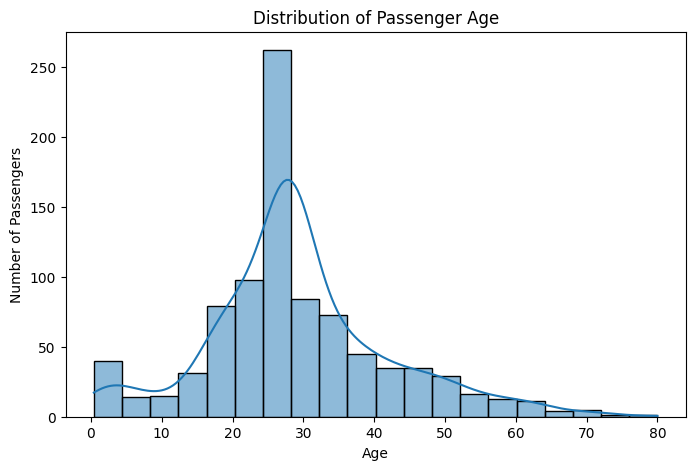

In [ ]:
# --------------------------------------------
# 4. HISTOGRAM OF AGE
# --------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(df["age"], bins=20, kde=True)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

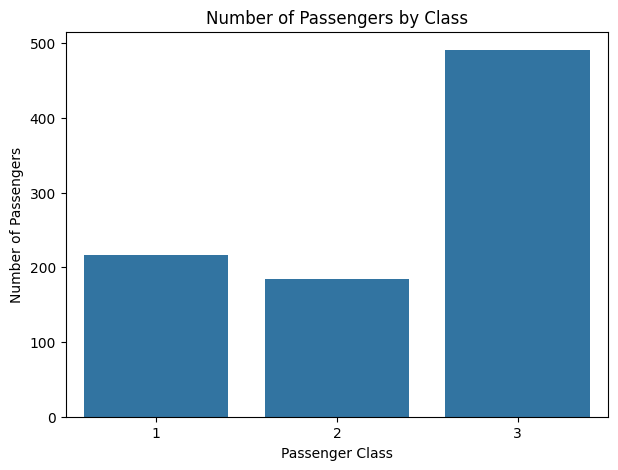

In [ ]:
#--------------------------------------------
# 5. BAR CHART - PASSENGER CLASS
# --------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="pclass")

plt.title("Number of Passengers by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

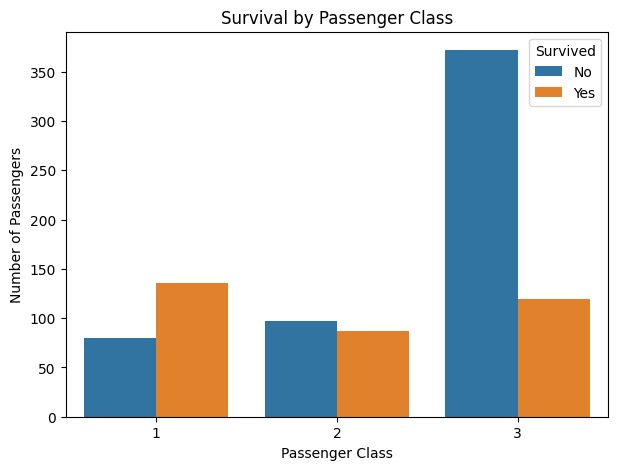

In [ ]:
# --------------------------------------------
# 6. SURVIVAL BY PASSENGER CLASS
# --------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="pclass", hue="survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survived",
    labels=["No", "Yes"]
)

plt.show()


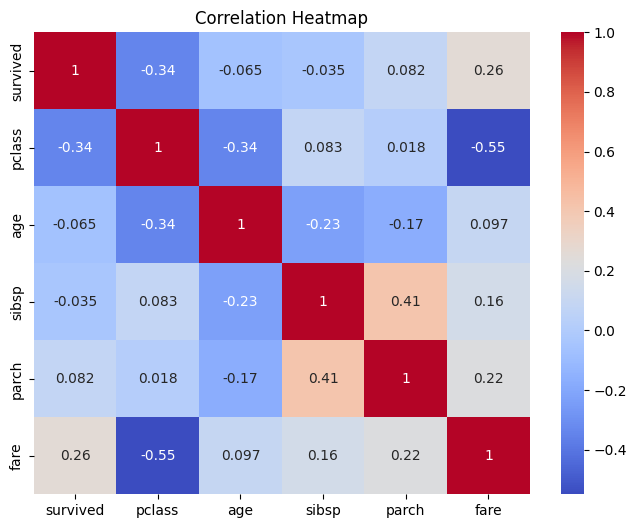

In [ ]:
# --------------------------------------------
# 7. CORRELATION HEATMAP
# --------------------------------------------

# Select numerical columns
numeric_data = df[
    ["survived", "pclass", "age", "sibsp", "parch", "fare"]
]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()


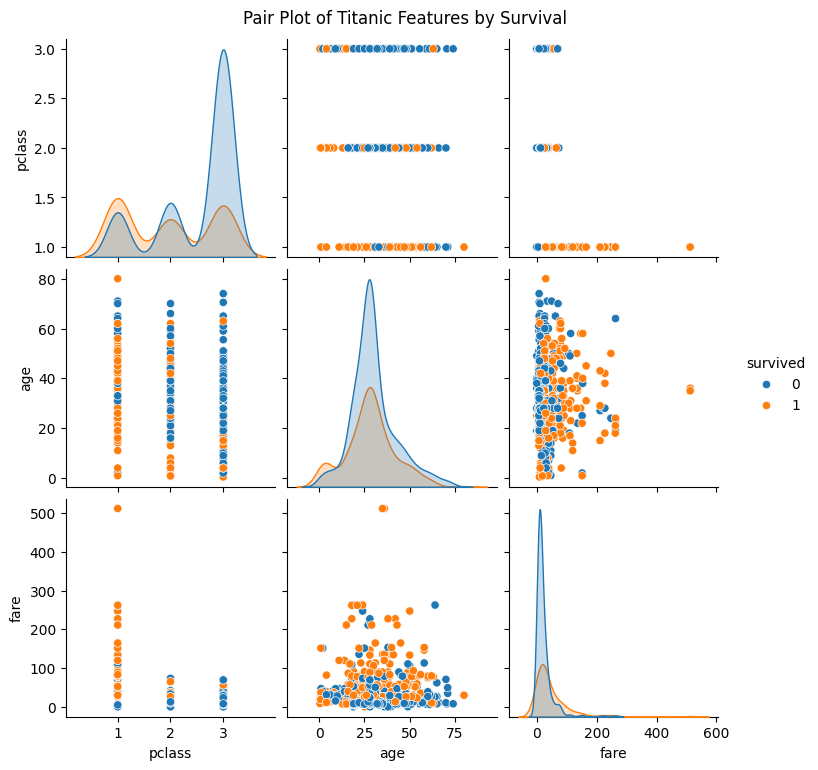

In [ ]:
# --------------------------------------------
# 8. PAIR PLOT
# --------------------------------------------

pair_data = df[
    ["survived", "pclass", "age", "fare"]
]

sns.pairplot(
    pair_data,
    hue="survived"
)

plt.suptitle(
    "Pair Plot of Titanic Features by Survival",
    y=1.02
)

plt.show()


In [ ]:
# --------------------------------------------
# 9. SIMPLE SURVIVAL SUMMARY
# --------------------------------------------

print("\nSurvival Count:")
print(df["survived"].value_counts())

print("\nSurvival Percentage:")
print(df["survived"].value_counts(normalize=True) * 100)


Survival Count:
survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


## **Lab Program 2**

# ***Perform  exploratory  analysis  on  an  IoT  smart  home  dataset  (temperature,  humidity,  motion, timestamp).  Clean  missing  values,  visualize  trends,  detect  anomalies,  and  summarize***

In [ ]:
# ============================================
# IoT SMART HOME DATASET - EDA
# Beginner Level
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------

df = pd.read_csv("smart_home_raw.csv")

print("First 5 rows:")
print(df.head())


# ------------------------------------------------
# 2. UNDERSTAND THE DATA
# ------------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())



First 5 rows:
   temperature  humidity  motion            timestamp
0        22.69     42.96     0.0  2025-01-04 15:30:00
1        21.12     44.62     0.0  2025-01-18 18:30:00
2        17.78     45.00     0.0  2025-01-12 22:30:00
3        17.65     48.31     0.0  2025-01-11 22:45:00
4        17.23     46.86     0.0  2025-01-01 02:15:00

Dataset Shape:
(2008, 4)

Column Names:
Index(['temperature', 'humidity', 'motion', 'timestamp'], dtype='object')

Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2008 entries, 0 to 2007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  1928 non-null   float64
 1   humidity     1908 non-null   float64
 2   motion       1947 non-null   float64
 3   timestamp    2008 non-null   object 
dtypes: float64(3), object(1)
memory usage: 62.9+ KB
None

Missing Values:
temperature     80
humidity       100
motion          61
timestamp        0
dtype: int64


In [ ]:
# ------------------------------------------------
# 3. CONVERT TIMESTAMP
# ------------------------------------------------

df["timestamp"] = pd.to_datetime(df["timestamp"])

# Sort data according to time
df = df.sort_values("timestamp")

print("\nTimestamp converted successfully.")


# ------------------------------------------------
# 4. CLEAN MISSING VALUES
# ------------------------------------------------

# Fill missing temperature with median
df["temperature"] = df["temperature"].fillna(
    df["temperature"].median()
)

# Fill missing humidity with median
df["humidity"] = df["humidity"].fillna(
    df["humidity"].median()
)

# Fill missing motion with mode
df["motion"] = df["motion"].fillna(
    df["motion"].mode()[0]
)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nData types after cleaning:")
print(df.dtypes)




Timestamp converted successfully.

Missing Values After Cleaning:
temperature    0
humidity       0
motion         0
timestamp      0
dtype: int64

Data types after cleaning:
temperature           float64
humidity              float64
motion                float64
timestamp      datetime64[ns]
dtype: object



Basic Statistics:
       temperature     humidity       motion
count  2008.000000  2008.000000  2008.000000
mean     21.007744    44.768277     0.314243
std       2.894593     4.534026     0.464329
min      -0.180000     0.000000     0.000000
25%      18.630000    42.565000     0.000000
50%      21.025000    44.785000     0.000000
75%      23.302500    47.252500     1.000000
max      44.420000    99.930000     1.000000


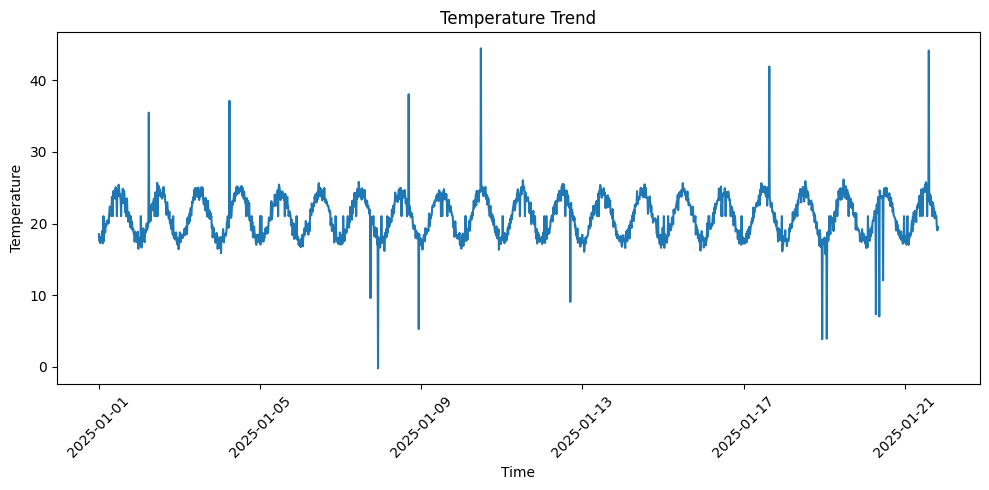

In [ ]:
# ------------------------------------------------
# 5. BASIC STATISTICS
# ------------------------------------------------

print("\nBasic Statistics:")
print(df[["temperature", "humidity", "motion"]].describe())


# ------------------------------------------------
# 6. TEMPERATURE TREND
# ------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot( df["timestamp"], df["temperature"] )

plt.title("Temperature Trend")
plt.xlabel("Time")
plt.ylabel("Temperature")

plt.xticks(rotation=45)D

plt.tight_layout()
plt.show()


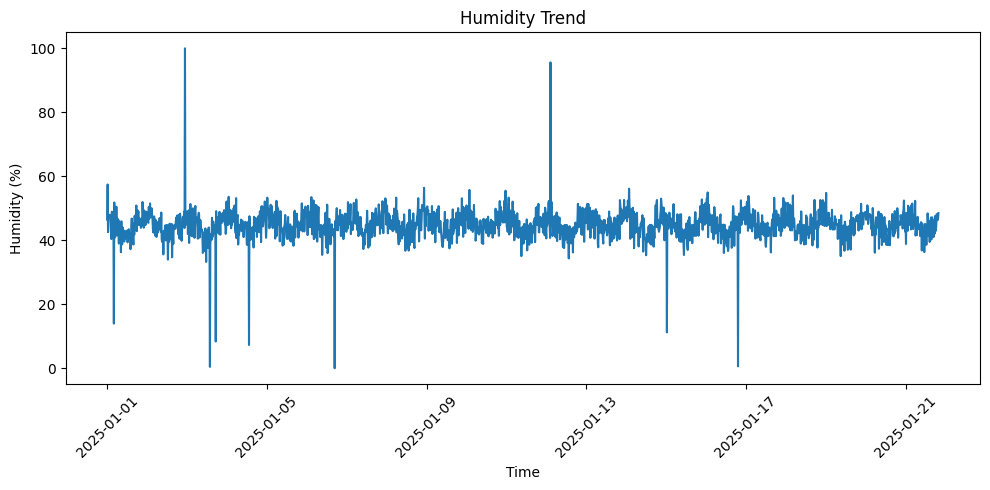

In [ ]:
# ------------------------------------------------
# 7. HUMIDITY TREND
# ------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    df["timestamp"],
    df["humidity"]
)

plt.title("Humidity Trend")
plt.xlabel("Time")
plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


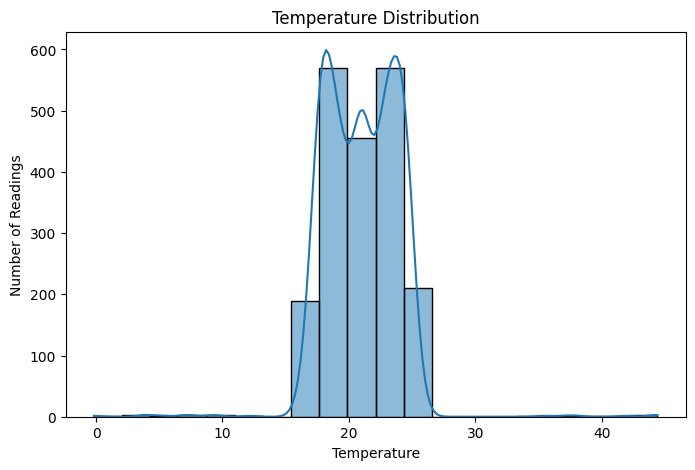

In [ ]:
# ------------------------------------------------
# 8. TEMPERATURE DISTRIBUTION
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    df["temperature"],
    bins=20,
    kde=True
)

plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Number of Readings")

plt.show()

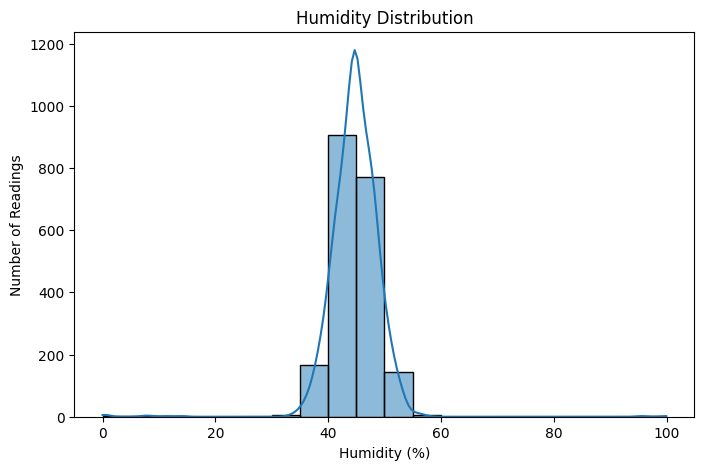

In [ ]:
# ------------------------------------------------
# 9. HUMIDITY DISTRIBUTION
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    df["humidity"],
    bins=20,
    kde=True
)

plt.title("Humidity Distribution")
plt.xlabel("Humidity (%)")
plt.ylabel("Number of Readings")

plt.show()


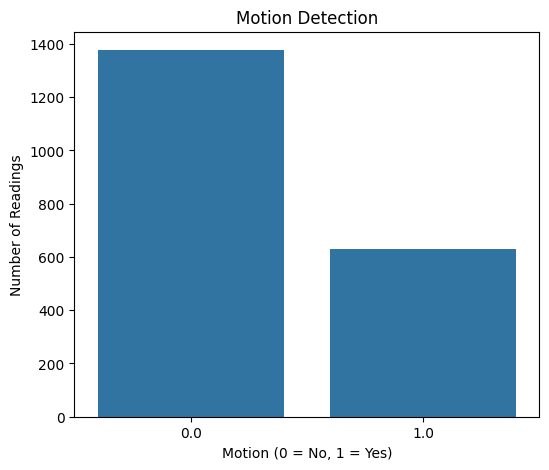

In [ ]:

# ------------------------------------------------
# 10. MOTION DETECTION COUNT
# ------------------------------------------------

plt.figure(figsize=(6, 5))

sns.countplot(
    data=df,
    x="motion"
)

plt.title("Motion Detection")
plt.xlabel("Motion (0 = No, 1 = Yes)")
plt.ylabel("Number of Readings")

plt.show()


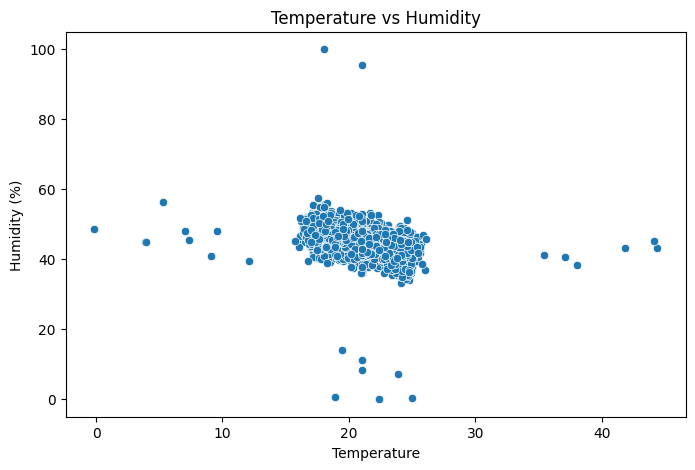

In [ ]:
# ------------------------------------------------
# 11. TEMPERATURE VS HUMIDITY
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity"
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature")
plt.ylabel("Humidity (%)")

plt.show()

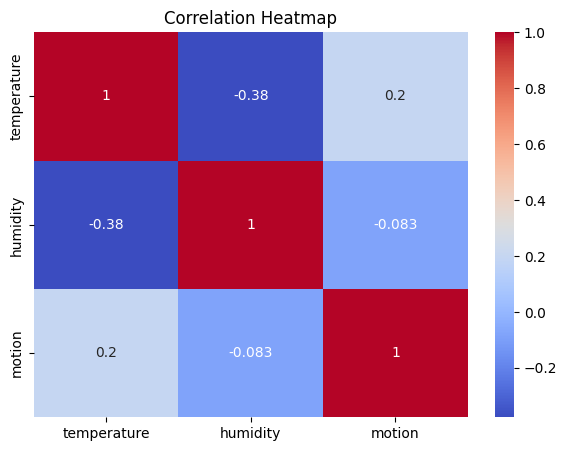

In [ ]:
# ------------------------------------------------
# 12. CORRELATION HEATMAP
# ------------------------------------------------

numeric_data = df[
    ["temperature", "humidity", "motion"]
]

correlation = numeric_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()


In [ ]:
# ------------------------------------------------
# 13. DETECT ANOMALIES USING IQR
# ------------------------------------------------

# Function to find anomalies
def find_anomalies(column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    anomalies = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    return anomalies


# Find temperature anomalies
temperature_anomalies = find_anomalies("temperature")

print("\nTemperature Anomalies:")
print(temperature_anomalies)


# Find humidity anomalies
humidity_anomalies = find_anomalies("humidity")

print("\nHumidity Anomalies:")
print(humidity_anomalies)


# ------------------------------------------------
# 14. DISPLAY NUMBER OF ANOMALIES
# ------------------------------------------------

print("\nNumber of Temperature Anomalies:")
print(len(temperature_anomalies))

print("\nNumber of Humidity Anomalies:")
print(len(humidity_anomalies))


Temperature Anomalies:
      temperature  humidity  motion           timestamp
346         35.46    41.150     0.0 2025-01-02 05:45:00
1991        37.10    40.620     0.0 2025-01-04 05:45:00
1577         9.60    48.170     1.0 2025-01-07 17:45:00
852         -0.18    48.510     0.0 2025-01-07 22:15:00
1330        38.02    38.360     0.0 2025-01-08 16:30:00
1214         5.29    56.360     0.0 2025-01-08 22:30:00
660         44.42    43.310     1.0 2025-01-10 11:30:00
1685         9.08    40.940     0.0 2025-01-12 16:45:00
1870        41.88    43.250     1.0 2025-01-17 15:15:00
1564         3.87    44.785     1.0 2025-01-18 22:45:00
226          3.94    44.785     0.0 2025-01-19 01:30:00
13           7.35    45.380     0.0 2025-01-20 06:45:00
1832         7.04    47.930     1.0 2025-01-20 08:45:00
403         44.12    45.280     0.0 2025-01-21 14:15:00

Humidity Anomalies:
      temperature  humidity  motion           timestamp
519        17.560     57.40     0.0 2025-01-01 00:15:00
335

In [ ]:
# ------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------

print("\n========== SMART HOME DATA SUMMARY ==========")

print(
    "Average Temperature:",
    round(df["temperature"].mean(), 2)
)

print(
    "Average Humidity:",
    round(df["humidity"].mean(), 2)
)

print(
    "Minimum Temperature:",
    round(df["temperature"].min(), 2)
)

print(
    "Maximum Temperature:",
    round(df["temperature"].max(), 2)
)

print(
    "Minimum Humidity:",
    round(df["humidity"].min(), 2)
)

print(
    "Maximum Humidity:",
    round(df["humidity"].max(), 2)
)

print(
    "Total Motion Detected:",
    int(df["motion"].sum())
)

print(
    "Temperature Anomalies:",
    len(temperature_anomalies)
)

print(
    "Humidity Anomalies:",
    len(humidity_anomalies)
)


========== SMART HOME DATA SUMMARY ==========
Average Temperature: 21.01
Average Humidity: 44.77
Minimum Temperature: -0.18
Maximum Temperature: 44.42
Minimum Humidity: 0.0
Maximum Humidity: 99.93
Total Motion Detected: 631
Temperature Anomalies: 14
Humidity Anomalies: 25


<Axes: xlabel='humidity', ylabel='Count'>

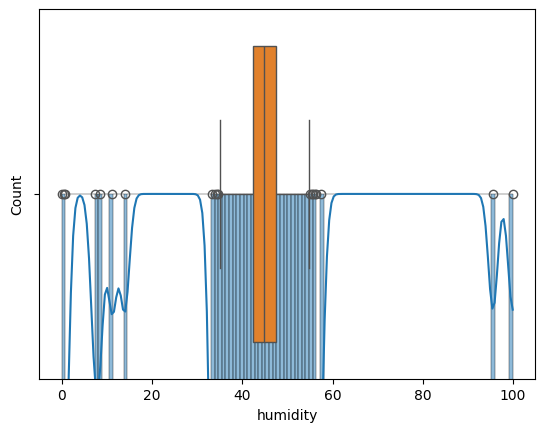

In [ ]:
import pandas as pd
from scipy import stats

# Using pandas
df["humidity"].skew()

# Using scipy (same underlying calculation)
stats.skew(df["humidity"])

# Visual check
import seaborn as sns
sns.histplot(df["humidity"], kde=True)
sns.boxplot(x=df["humidity"])
# a long whisker on one side signals skew

